# Scope and Limitations

Notes and checks for the Scope and Limitations section of our proposal on socioeconomic
conditions and Medicare spending across U.S. counties.

## 1. Scope

We run main.ipynb so we are working with exactly the same data as the main analysis, and we do
not reload or rebuild anything here. That gives us cms for the raw file, cms_2023 for the 2023
county all-age rows, acs for the ACS estimates, and merged for the joined data.

In [1]:
%%capture
%run main.ipynb

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [3]:
# These load as text because CMS writes '*' for suppressed cells
for col in ["MA_PRTCPTN_RATE", "BENES_OM_CNT", "BENE_AVG_AGE", "BENE_DUAL_PCT"]:
    merged[col] = pd.to_numeric(merged[col], errors="coerce")

merged[["medicare_spending", "MA_PRTCPTN_RATE", "BENES_OM_CNT"]].dtypes

medicare_spending    float64
MA_PRTCPTN_RATE      float64
BENES_OM_CNT         float64
dtype: object

In [4]:
print("Raw CMS rows:     ", len(cms))
print("Filtered CMS rows:", len(cms_2023))
print("ACS rows:         ", len(acs))
print("Merged rows:      ", len(merged))

print("\nOutcome and predictors only:", len(merged.dropna(
    subset=["medicare_spending", "median_household_income",
            "poverty_rate", "unemployment_rate"])))
print("Models 1 and 2:            ", len(merged.dropna(
    subset=["medicare_spending", "median_household_income",
            "poverty_rate", "unemployment_rate",
            "BENE_AVG_AGE", "BENE_DUAL_PCT"])))
print("Model 3:                   ", len(merged.dropna(
    subset=["medicare_spending", "median_household_income",
            "poverty_rate", "unemployment_rate",
            "BENE_AVG_AGE", "BENE_DUAL_PCT", "MA_PRTCPTN_RATE"])))

Raw CMS rows:      36994
Filtered CMS rows: 3197
ACS rows:          3222
Merged rows:       3143

Outcome and predictors only: 3140
Models 1 and 2:             3121
Model 3:                    3107


In [5]:
# Confirm the filters main.ipynb applied
print(cms_2023["YEAR"].unique(), cms_2023["BENE_GEO_LVL"].unique(), cms_2023["BENE_AGE_LVL"].unique())

print("\nNon-missing counts:")
print(merged[["medicare_spending", "median_household_income", "poverty_rate",
              "unemployment_rate", "BENE_AVG_AGE", "BENE_DUAL_PCT",
              "MA_PRTCPTN_RATE"]].notna().sum())

[2023] ['County'] ['All']

Non-missing counts:
medicare_spending          3142
median_household_income    3141
poverty_rate               3143
unemployment_rate          3143
BENE_AVG_AGE               3142
BENE_DUAL_PCT              3122
MA_PRTCPTN_RATE            3126
dtype: int64


We have 3,143 merged counties. Dropping missing values on the outcome and the three
socioeconomic predictors leaves 3,140, but once the beneficiary controls are added the samples
our models actually use are 3,121 for Models 1 and 2 and 3,107 for Model 3. The extra losses
come from the dual-eligible and Medicare Advantage shares, which are missing for a few counties.

## 2. FIPS matching

The two files do not cover exactly the same geographies, so we checked what drops out of the
join on each side.

In [6]:
print("In CMS but not ACS:", (~cms_2023["fips"].isin(acs["fips"])).sum())
print("In ACS but not CMS:", (~acs["fips"].isin(cms_2023["fips"])).sum())

print("\nCMS records with no match:")
print(cms_2023[~cms_2023["fips"].isin(acs["fips"])]["BENE_GEO_DESC"].tolist())

In CMS but not ACS: 54
In ACS but not CMS: 79

CMS records with no match:
['AK-UNKNOWN', 'AL-UNKNOWN', 'AR-UNKNOWN', 'AZ-UNKNOWN', 'CA-UNKNOWN', 'CO-UNKNOWN', 'CT-UNKNOWN', 'DE-UNKNOWN', 'FL-UNKNOWN', 'GA-UNKNOWN', 'HI-UNKNOWN', 'IA-UNKNOWN', 'ID-UNKNOWN', 'IL-UNKNOWN', 'IN-UNKNOWN', 'KS-UNKNOWN', 'KY-UNKNOWN', 'LA-UNKNOWN', 'MA-UNKNOWN', 'MD-UNKNOWN', 'ME-UNKNOWN', 'MI-UNKNOWN', 'MN-UNKNOWN', 'MO-UNKNOWN', 'MS-UNKNOWN', 'MT-UNKNOWN', 'NC-UNKNOWN', 'ND-UNKNOWN', 'NE-UNKNOWN', 'NH-UNKNOWN', 'NJ-UNKNOWN', 'NM-UNKNOWN', 'NV-UNKNOWN', 'NY-UNKNOWN', 'OH-UNKNOWN', 'OK-UNKNOWN', 'OR-UNKNOWN', 'PA-UNKNOWN', 'RI-UNKNOWN', 'SC-UNKNOWN', 'SD-UNKNOWN', 'TN-UNKNOWN', 'TX-UNKNOWN', 'UT-UNKNOWN', 'VA-UNKNOWN', 'VI-St. Croix', 'VI-St. John', 'VI-St. Thomas', 'VI-UNKNOWN', 'VT-UNKNOWN', 'WA-UNKNOWN', 'WI-UNKNOWN', 'WV-UNKNOWN', 'WY-UNKNOWN']


In [7]:
# State name is the last piece of the ACS county name
print("ACS records with no match, by state:")
print(
    acs[~acs["fips"].isin(cms_2023["fips"])]["county_name"]
    .str.split(", ").str[-1].value_counts()
)

# CMS does carry DC and PR, but only as states
print("\nHow CMS stores DC and PR in 2023:")
print(
    cms[(cms["YEAR"] == 2023) & (cms["BENE_GEO_DESC"].isin(["DC", "PR"]))]
    [["BENE_GEO_LVL", "BENE_GEO_DESC"]].drop_duplicates()
)

ACS records with no match, by state:
county_name
Puerto Rico             78
District of Columbia     1
Name: count, dtype: int64

How CMS stores DC and PR in 2023:
      BENE_GEO_LVL BENE_GEO_DESC
30613        State            DC
32734        State            PR


In [8]:
# Connecticut switched from counties to planning regions, so we checked it separately
print("CT in CMS:   ", (cms_2023["fips"].str[:2] == "09").sum())
print("CT in ACS:   ", (acs["fips"].str[:2] == "09").sum())
print("CT in merged:", (merged["fips"].str[:2] == "09").sum())

CT in CMS:    10
CT in ACS:    9
CT in merged: 9


We lose 54 CMS records and 79 ACS records, but none of them are real counties. The CMS side is
51 placeholder rows coded as a state abbreviation plus UNKNOWN, with FIPS ending in 000, plus
the three U.S. Virgin Islands districts. The ACS side is the District of Columbia and the 78
Puerto Rico municipios, which CMS only reports at the state level. All nine Connecticut planning
regions matched, so our results cover the 50 states and exclude DC and the territories.

## 3. Fee-for-service population only

The spending measure only covers fee-for-service beneficiaries, so we looked at how large the
Medicare Advantage share is across counties. CMS stores MA_PRTCPTN_RATE as a proportion, so 0.5
is a 50 percent share.

In [9]:
print(merged["MA_PRTCPTN_RATE"].describe())
print("\nCounties with MA share above 50%:", (merged["MA_PRTCPTN_RATE"] > 0.5).sum())
print("Counties with no MA share reported:", merged["MA_PRTCPTN_RATE"].isna().sum())

count    3126.000000
mean        0.439286
std         0.167794
min         0.000000
25%         0.336300
50%         0.458500
75%         0.562400
max         0.813200
Name: MA_PRTCPTN_RATE, dtype: float64

Counties with MA share above 50%: 1252
Counties with no MA share reported: 17


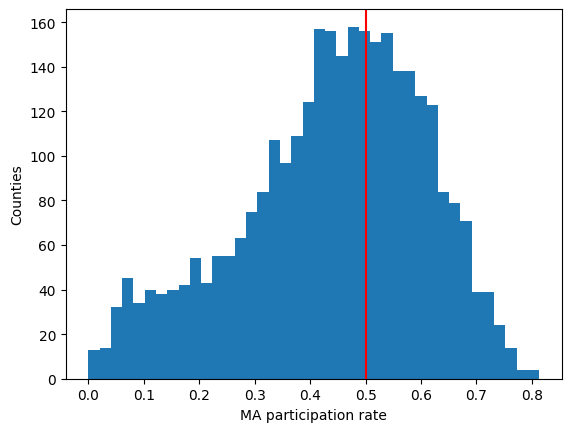

In [10]:
plt.hist(merged["MA_PRTCPTN_RATE"].dropna(), bins=40)
plt.axvline(0.5, color="red")
plt.xlabel("MA participation rate")
plt.ylabel("Counties")
plt.show()

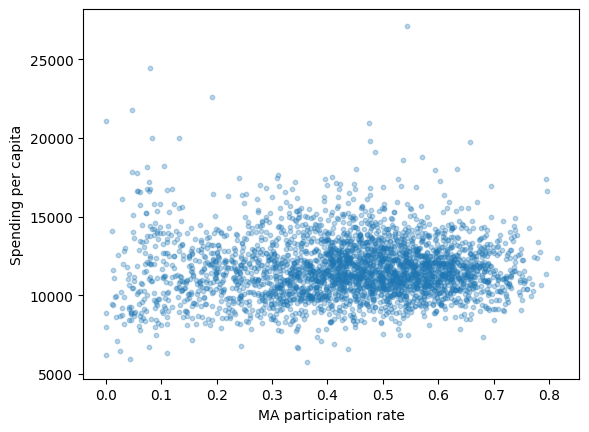

Correlation: 0.029


In [11]:
plt.scatter(merged["MA_PRTCPTN_RATE"], merged["medicare_spending"], alpha=0.3, s=10)
plt.xlabel("MA participation rate")
plt.ylabel("Spending per capita")
plt.show()

print("Correlation:", round(merged["MA_PRTCPTN_RATE"].corr(merged["medicare_spending"]), 3))

We found that the Medicare Advantage share averages about 44 percent and is above 50 percent in
1,252 counties, so in roughly 40 percent of counties our outcome describes a minority of
beneficiaries. The correlation with spending is almost zero, which is reassuring, but it does
not rule out the possibility that the people who stay in fee-for-service differ from those who
switch in ways that also track county economic conditions.

## 4. Small counties and measurement error

Per-capita spending is a noisier estimate when a county has very few beneficiaries, so we
compared the smallest counties with the rest using the bottom decile as the cutoff.

In [12]:
print(merged["BENES_OM_CNT"].describe())

cutoff = merged["BENES_OM_CNT"].quantile(0.10)
print("\nBottom decile cutoff:", round(cutoff))

count      3142.000000
mean       8991.393062
std       21718.911453
min          11.000000
25%        1416.250000
50%        3025.500000
75%        7482.750000
max      542792.000000
Name: BENES_OM_CNT, dtype: float64

Bottom decile cutoff: 682


In [13]:
print(merged.groupby(merged["BENES_OM_CNT"] <= cutoff)["medicare_spending"].agg(
    ["count", "mean", "std", "var"]
))

print("\nSmall county SD:", round(merged[merged["BENES_OM_CNT"] <= cutoff]["medicare_spending"].std()))
print("Large county SD:", round(merged[merged["BENES_OM_CNT"] > cutoff]["medicare_spending"].std()))

              count          mean          std           var
BENES_OM_CNT                                                
False          2827  11604.554927  1718.414413  2.952948e+06
True            315  12107.481143  2990.660477  8.944050e+06

Small county SD: 2991
Large county SD: 1718


Fee-for-service counts run from 11 to about 543,000 with a median near 3,000, so counties are
measured with very different precision. In the bottom decile the standard deviation of spending
is about \$2,991 against \$1,718 everywhere else, and the variance column shows roughly three
times the spread. Some of that is probably noise rather than real variation, which is one reason
we report robust standard errors.

## 5. Multicollinearity

Income, poverty, and unemployment all measure related things, so we checked the correlations and
variance inflation factors for the Model 3 predictors.

In [14]:
model_cols = ["median_household_income", "poverty_rate", "unemployment_rate",
              "BENE_AVG_AGE", "BENE_DUAL_PCT", "MA_PRTCPTN_RATE"]

print("Observations:", len(merged[model_cols].dropna()))
print(merged[model_cols].dropna().corr().round(3))

Observations: 3107
                         median_household_income  poverty_rate  \
median_household_income                    1.000        -0.733   
poverty_rate                              -0.733         1.000   
unemployment_rate                         -0.320         0.539   
BENE_AVG_AGE                               0.263        -0.355   
BENE_DUAL_PCT                             -0.398         0.567   
MA_PRTCPTN_RATE                           -0.107         0.209   

                         unemployment_rate  BENE_AVG_AGE  BENE_DUAL_PCT  \
median_household_income             -0.320         0.263         -0.398   
poverty_rate                         0.539        -0.355          0.567   
unemployment_rate                    1.000        -0.331          0.451   
BENE_AVG_AGE                        -0.331         1.000         -0.604   
BENE_DUAL_PCT                        0.451        -0.604          1.000   
MA_PRTCPTN_RATE                      0.249        -0.444          0.

In [15]:
# i + 1 skips the constant column that add_constant puts first
pd.DataFrame({
    "variable": model_cols,
    "VIF": [
        variance_inflation_factor(sm.add_constant(merged[model_cols].dropna()).values, i + 1)
        for i in range(len(model_cols))
    ],
}).round(2)

,variable,VIF
0,median_household_income,2.22
1,poverty_rate,3.14
2,unemployment_rate,1.53
3,BENE_AVG_AGE,1.86
4,BENE_DUAL_PCT,2.09
5,MA_PRTCPTN_RATE,1.28


Income and poverty are strongly correlated at r = -0.733, and the dual-eligible share is
correlated with both. Even so, the highest VIF is only 3.14 on the poverty rate, well under the
usual cutoff of 5, so we do not need to drop anything. The issue is more about interpretation,
since each coefficient only picks up the variation that variable does not share with the others.

## 6. Other limitations

Our unit of analysis is the county, not the individual, so any association we find describes
county averages and cannot be read as telling us about individual beneficiaries without running
into the ecological fallacy. The design is also observational and cross-sectional, so we can
report adjusted associations but not causal effects, and things like local health care supply
and state Medicaid policy stay uncontrolled. The two sources also do not line up in time, since
our CMS outcome is calendar year 2023 while the ACS 5-Year estimates pool 2019 through 2023 and
average across the COVID period. That mismatch probably weakens the associations we estimate,
especially for unemployment, which moved the most during those years.